In [1]:
import os
import re
import sqlite3
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels.api as sm
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import classification_report, mean_absolute_error, mean_squared_error

warnings.filterwarnings('ignore')

In [2]:
class TelegramIntelligenceExtractor:
    def __init__(self, db_path: Path):
        self.db_path = db_path
        self.patterns = {
            'strategic_bombers': re.compile(r'\b(ту-95|ту-22|ту-160|оленья|енгельс|борт[иів])\b', re.IGNORECASE),
            'mig31_ballistics': re.compile(r'\b(міг-31|міг-31к|кинджал|балістик|іскандер)\b', re.IGNORECASE),
            'uav_swarms': re.compile(r'\b(шахед|шахід|shahed|бпла|дрон|герань)\b', re.IGNORECASE),
            'kyiv_vector': re.compile(r'\b(київ|бориспіль|бровари|васильків|вишгород|напрямок києва)\b', re.IGNORECASE),
            'air_defense_kinetic': re.compile(r'\b(робота ппо|збито|вибух|відпрацювал)\b', re.IGNORECASE)
        }

    def fetch_text_features(self, cutoff_dates: pd.DatetimeIndex) -> pd.DataFrame:
        if not self.db_path.exists():
            print(f"Warning: OSINT Database not found at {self.db_path}. Returning empty features.")
            return pd.DataFrame(index=cutoff_dates)

        records = []
        conn = sqlite3.connect(str(self.db_path), timeout=30.0)
        
        for cutoff in cutoff_dates:
            t_24h = cutoff - pd.Timedelta(hours=24)
            t_6h = cutoff - pd.Timedelta(hours=6)
            
            query = """
                SELECT channel_username, timestamp_utc, text 
                FROM messages 
                WHERE timestamp_utc >= ? AND timestamp_utc < ?
            """
            df = pd.read_sql_query(query, conn, params=(t_24h.isoformat(), cutoff.isoformat()))
            if df.empty:
                continue
                
            df['timestamp_utc'] = pd.to_datetime(df['timestamp_utc'])
            obs_6h = df[df['timestamp_utc'] >= t_6h]
            
            features = {'cutoff_timestamp_utc': cutoff}
            texts_24h = df['text'].astype(str)
            features['text_bombers_24h'] = int(texts_24h.apply(lambda x: bool(self.patterns['strategic_bombers'].search(x))).sum())
            features['text_ballistics_24h'] = int(texts_24h.apply(lambda x: bool(self.patterns['mig31_ballistics'].search(x))).sum())
            features['text_kinetic_24h'] = int(texts_24h.apply(lambda x: bool(self.patterns['air_defense_kinetic'].search(x))).sum())
            
            texts_6h = obs_6h['text'].astype(str)
            features['text_uav_surge_6h'] = int(texts_6h.apply(lambda x: bool(self.patterns['uav_swarms'].search(x))).sum())
            features['text_kyiv_vector_6h'] = int(texts_6h.apply(lambda x: bool(self.patterns['kyiv_vector'].search(x))).sum())
            
            records.append(features)
            
        conn.close()
        
        if not records:
            return pd.DataFrame(index=cutoff_dates)
            
        features_df = pd.DataFrame(records).set_index('cutoff_timestamp_utc')
        features_df.index = features_df.index.normalize()
        return features_df

In [10]:
class MultimodalPipeline:
    def __init__(self, raw_csv_url: str, db_path: Path, cutoff_date: str = '2026-10-11'):
        self.raw_url = raw_csv_url
        self.db_path = db_path
        self.cutoff_date = pd.to_datetime(cutoff_date).tz_localize('UTC')

    def build_fused_dataset(self, target_region: str = 'Kyiv City') -> pd.DataFrame:
        print("Fetching historical air raid dataset...")
        df = pd.read_csv(self.raw_url)
        df['started_at'] = pd.to_datetime(df['started_at'])
        df['finished_at'] = pd.to_datetime(df['finished_at'])

        df = df[df['started_at'] <= self.cutoff_date].dropna(subset=['finished_at'])
        
        target_df = df[df['region'] == target_region].set_index('started_at')
        daily_alerts = target_df.resample('D').size().rename('total_alerts')
        
        base_df = pd.DataFrame(daily_alerts).fillna(0)
        base_df.index = base_df.index.normalize()

        print("Extracting OSINT text intelligence...")
        extractor = TelegramIntelligenceExtractor(self.db_path)
        text_features = extractor.fetch_text_features(base_df.index)

        if not text_features.empty:
            fused_df = pd.merge_asof(
                base_df.sort_index(),
                text_features.sort_index(),
                left_index=True,
                right_index=True,
                direction='backward'
            ).fillna(0)
        else:
            fused_df = base_df.copy()

        
        return fused_df

In [11]:
class TimeSeriesRiskTrainer:
    def __init__(self, feature_df: pd.DataFrame, test_days: int = 60):
        self.df = feature_df
        self.test_days = test_days
        
        max_date = self.df.index.max()
        self.split_date = max_date - pd.Timedelta(days=self.test_days)

        self.exog_cols = [c for c in self.df.columns if c != 'total_alerts']
        self.y = self.df['total_alerts']
        self.X_exog = self.df[self.exog_cols]

    def execute_rolling_forecast(self):
        y_train = self.y[self.y.index < self.split_date]
        y_test = self.y[self.y.index >= self.split_date]
        
        X_train = self.X_exog[self.X_exog.index < self.split_date]
        X_test = self.X_exog[self.X_exog.index >= self.split_date]

        print(f"Training on {len(y_train)} days, Testing walk-forward on {len(y_test)} days...")

        history_y = list(y_train.values)
        history_X = list(X_train.values)
        
        arima_preds = []
        sarimax_preds = []

        # Walk-forward validation loop
        for t in range(len(y_test)):
            if t % 15 == 0:
                print(f"  -> Processing step {t+1}/{len(y_test)}...")
                
            # 1. Baseline ARIMA (1,0,1) - Target only, no OSINT
            model_arima = SARIMAX(history_y, order=(1, 0, 1), enforce_stationarity=False, enforce_invertibility=False)
            res_arima = model_arima.fit(disp=False)
            arima_preds.append(max(0, res_arima.forecast(steps=1)[0]))

            # 2. Advanced SARIMAX (1,0,1) - Target + OSINT Exogenous features
            model_sarimax = SARIMAX(history_y, exog=history_X, order=(1, 0, 1), enforce_stationarity=False, enforce_invertibility=False)
            res_sarimax = model_sarimax.fit(disp=False, maxiter=200, method='lbfgs')
            
            current_exog = X_test.iloc[t].values.reshape(1, -1)
            sarimax_preds.append(max(0, res_sarimax.forecast(steps=1, exog=current_exog)[0]))

            # Update history with the true observation for the next step
            history_y.append(y_test.iloc[t])
            history_X.append(X_test.iloc[t].values)

        # Evaluate Regression Metrics
        print("\n--- Regression Metrics (Continuous Counts) ---")
        print(f"ARIMA (Baseline) MAE: {mean_absolute_error(y_test, arima_preds):.3f}")
        print(f"SARIMAX (OSINT)  MAE: {mean_absolute_error(y_test, sarimax_preds):.3f}")

        # Evaluate as Classification (High Risk Threshold: >= 3 Alerts)
        # We assume if the model predicts roughly 2.5 or more alerts, it is a high risk day.
        y_test_cls = (y_test >= 3).astype(int)
        arima_cls = (pd.Series(arima_preds) >= 2.5).astype(int)
        sarimax_cls = (pd.Series(sarimax_preds) >= 2.5).astype(int)

        print("\n--- Classification Metrics: High Risk (>=3 Alerts) ---")
        print("SARIMAX (with Telegram OSINT):")
        print(classification_report(y_test_cls, sarimax_cls, target_names=['Low Risk (<3)', 'High Risk (>=3)']))
        
        return y_test, arima_preds, sarimax_preds, res_sarimax

In [12]:
LOCAL_DB_PATH = Path(r"C:\Users\igorf\OneDrive\Documents\KSE\telegram_intel.db")
CSV_URL = "https://raw.githubusercontent.com/Vadimkin/ukrainian-air-raid-sirens-dataset/refs/heads/main/datasets/volunteer_data_en.csv"

pipeline = MultimodalPipeline(raw_csv_url=CSV_URL, db_path=LOCAL_DB_PATH)
fused_dataset = pipeline.build_fused_dataset(target_region='Kyiv City')

trainer = TimeSeriesRiskTrainer(fused_dataset, test_days=60)
y_test, arima_preds, sarimax_preds, final_sarimax_model = trainer.execute_rolling_forecast()

Fetching historical air raid dataset...
Extracting OSINT text intelligence...
Training on 1628 days, Testing walk-forward on 61 days...
  -> Processing step 1/61...
  -> Processing step 16/61...
  -> Processing step 31/61...
  -> Processing step 46/61...
  -> Processing step 61/61...

--- Regression Metrics (Continuous Counts) ---
ARIMA (Baseline) MAE: 1.605
SARIMAX (OSINT)  MAE: 1.557

--- Classification Metrics: High Risk (>=3 Alerts) ---
SARIMAX (with Telegram OSINT):
                 precision    recall  f1-score   support

  Low Risk (<3)       0.67      0.53      0.59        15
High Risk (>=3)       0.86      0.91      0.88        46

       accuracy                           0.82        61
      macro avg       0.76      0.72      0.74        61
   weighted avg       0.81      0.82      0.81        61



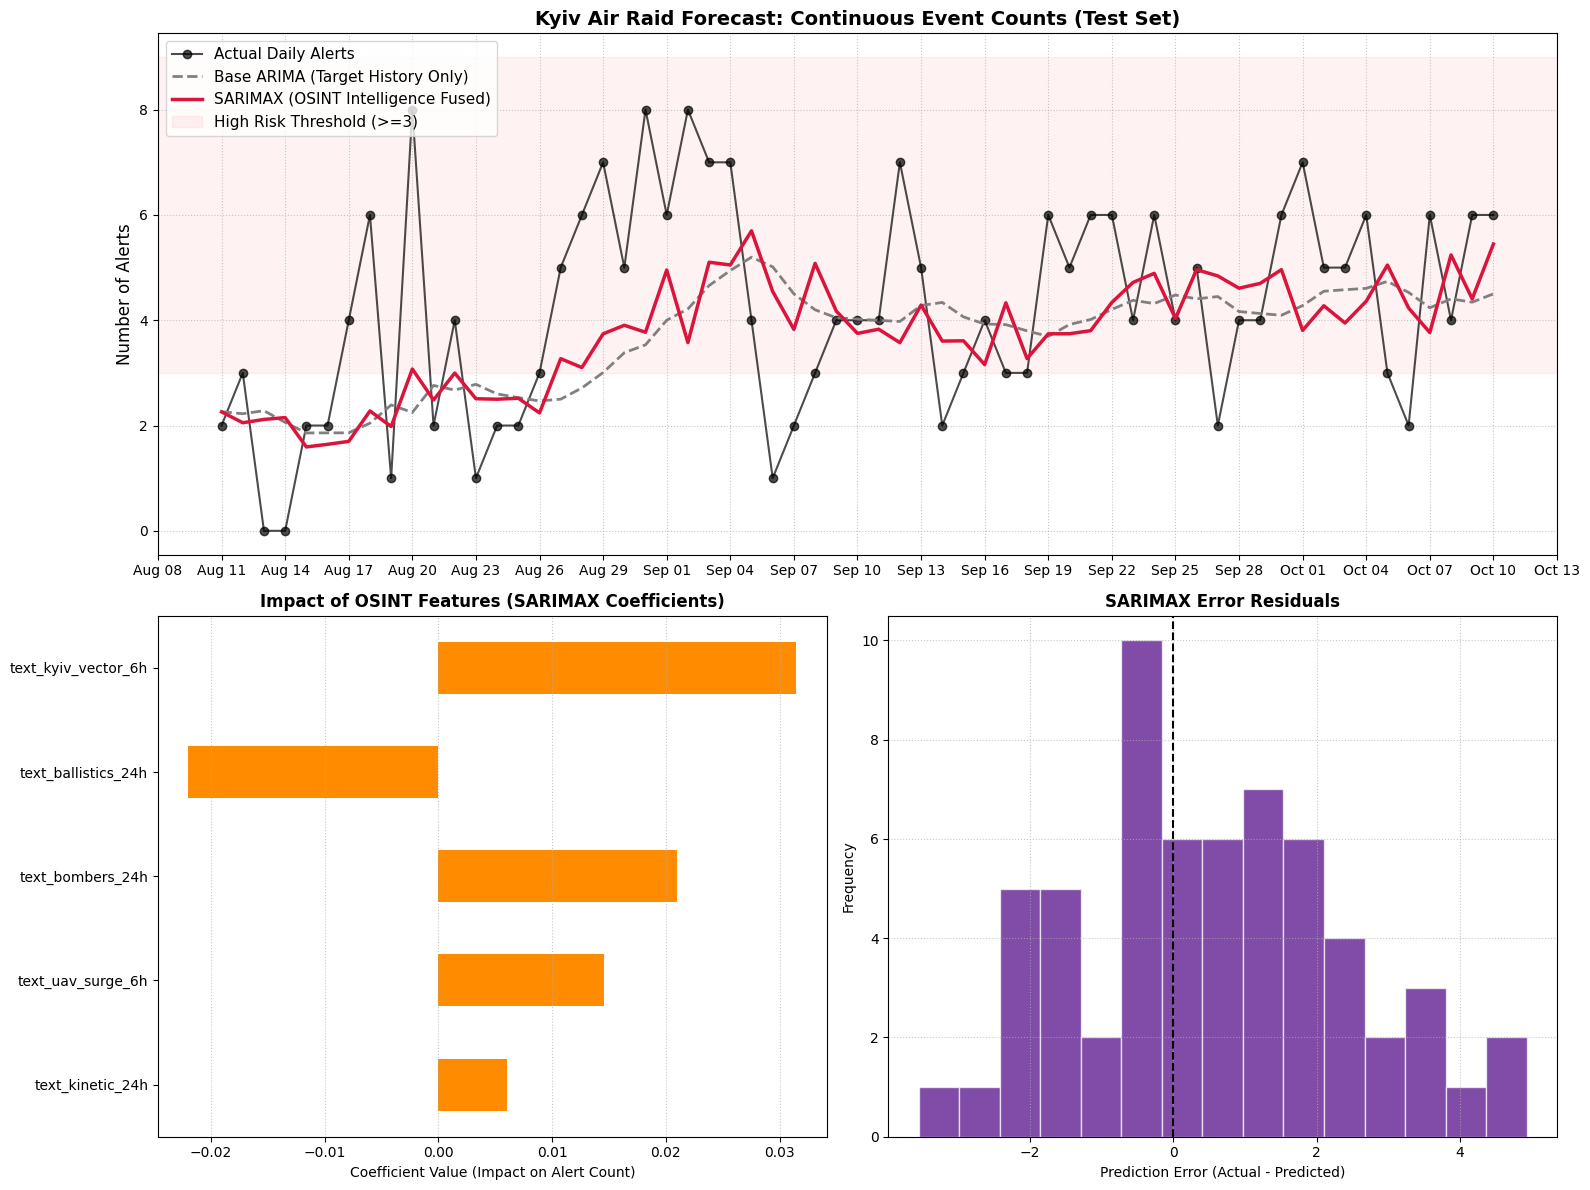

In [13]:
def visualize_sarimax_model(y_test, arima_preds, sarimax_preds, final_model, feature_names):
    fig = plt.figure(figsize=(16, 12))
    test_dates = y_test.index
    
    # --- SUBPLOT 1: Continuous Forecast Comparison ---
    ax1 = plt.subplot(2, 1, 1)
    ax1.plot(test_dates, y_test.values, color='black', marker='o', alpha=0.7, label='Actual Daily Alerts')
    ax1.plot(test_dates, arima_preds, color='gray', linestyle='--', linewidth=2, label='Base ARIMA (Target History Only)')
    ax1.plot(test_dates, sarimax_preds, color='crimson', linewidth=2.5, label='SARIMAX (OSINT Intelligence Fused)')
    
    # Highlight high risk zone
    ax1.axhspan(3, max(max(y_test), max(sarimax_preds)) + 1, color='red', alpha=0.05, label='High Risk Threshold (>=3)')
    
    ax1.set_title('Kyiv Air Raid Forecast: Continuous Event Counts (Test Set)', fontsize=14, fontweight='bold')
    ax1.set_ylabel('Number of Alerts', fontsize=12)
    ax1.grid(True, linestyle=':', alpha=0.7)
    ax1.legend(loc='upper left', fontsize=11)
    
    ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    ax1.xaxis.set_major_locator(mdates.DayLocator(interval=3))
    
    # --- SUBPLOT 2: OSINT Feature Impact (SARIMAX Coefficients) ---
    ax2 = plt.subplot(2, 2, 3)
    
    # Extract coefficients for the exogenous variables (excluding AR and MA terms)
    # statsmodels prefixes exogenous vars, we align them with feature_names
    params = final_model.params
    exog_params = pd.Series(params[:len(feature_names)], index=feature_names)
    
    # Sort by absolute magnitude of the impact
    exog_params_sorted = exog_params.reindex(exog_params.abs().sort_values(ascending=True).index)
    
    colors = ['darkorange' if 'text' in str(idx) else 'teal' for idx in exog_params_sorted.index]
    exog_params_sorted.tail(10).plot(kind='barh', ax=ax2, color=colors)
    
    ax2.set_title('Impact of OSINT Features (SARIMAX Coefficients)', fontsize=12, fontweight='bold')
    ax2.set_xlabel('Coefficient Value (Impact on Alert Count)')
    ax2.grid(True, axis='x', linestyle=':', alpha=0.7)
    
    # --- SUBPLOT 3: Residuals Distribution ---
    ax3 = plt.subplot(2, 2, 4)
    residuals = y_test.values - np.array(sarimax_preds)
    ax3.hist(residuals, bins=15, color='indigo', alpha=0.7, edgecolor='white')
    ax3.axvline(0, color='black', linestyle='--')
    
    ax3.set_title('SARIMAX Error Residuals', fontsize=12, fontweight='bold')
    ax3.set_xlabel('Prediction Error (Actual - Predicted)')
    ax3.set_ylabel('Frequency')
    ax3.grid(True, linestyle=':', alpha=0.7)
    
    plt.tight_layout()
    plt.show()

# Execute the visualization
visualize_sarimax_model(y_test, arima_preds, sarimax_preds, final_sarimax_model, trainer.exog_cols)

In [16]:
class LogScaledRiskTrainer:
    def __init__(self, feature_df: pd.DataFrame, test_days: int = 60):
        self.df = feature_df.copy()
        self.test_days = test_days
        
        self.split_date = self.df.index.max() - pd.Timedelta(days=self.test_days)

        self.exog_cols = [c for c in self.df.columns if c != 'total_alerts']
        
        # 1. APPLY TRANSFORMATION: log(1 + y) to compress outliers for training
        self.y_log = np.log1p(self.df['total_alerts'])
        self.y_actual = self.df['total_alerts']
        self.X_exog = self.df[self.exog_cols]

    def execute_log_forecast(self):
        # Split data chronologically
        y_train_log = self.y_log[self.y_log.index < self.split_date]
        y_test_actual = self.y_actual[self.y_actual.index >= self.split_date]
        
        X_train = self.X_exog[self.X_exog.index < self.split_date]
        X_test = self.X_exog[self.X_exog.index >= self.split_date]

        print(f"Training Log-Scaled SARIMAX on {len(y_train_log)} days, Testing on {len(y_test_actual)} days...")

        history_y_log = list(y_train_log.values)
        history_X = list(X_train.values)
        
        sarimax_preds_log = []

        # Walk-forward validation loop
        for t in range(len(y_test_actual)):
            if t % 15 == 0 and t > 0:
                print(f"  -> Processing step {t}/{len(y_test_actual)}...")

            model = SARIMAX(
                history_y_log, 
                exog=history_X, 
                order=(1, 0, 1), 
                enforce_stationarity=False, 
                enforce_invertibility=False
            )
            res = model.fit(disp=False, maxiter=200, method='lbfgs')
            
            current_exog = X_test.iloc[t].values.reshape(1, -1)
            pred_log = res.forecast(steps=1, exog=current_exog)[0]
            sarimax_preds_log.append(pred_log)

            # Append the ACTUAL observed log value to prevent drift
            history_y_log.append(np.log1p(y_test_actual.iloc[t]))
            history_X.append(X_test.iloc[t].values)

        # 2. REVERSE TRANSFORMATION: e^y - 1 to restore structural amplitude
        # We also enforce a hard zero floor since negative alerts are impossible
        sarimax_preds_restored = np.maximum(0, np.expm1(sarimax_preds_log))

        print("\n--- Model Evaluation (Restored Amplitude) ---")
        print(f"SARIMAX (Log-Scaled) MAE: {mean_absolute_error(y_test_actual, sarimax_preds_restored):.3f}")
        
        # High Risk Classification Eval (>= 3 Alerts)
        y_test_cls = (y_test_actual >= 3).astype(int)
        sarimax_cls = (pd.Series(sarimax_preds_restored) >= 2.5).astype(int)
        print("\nHigh Risk (>=3 Alerts) Detection:")
        print(classification_report(y_test_cls, sarimax_cls, target_names=['Low Risk (<3)', 'High Risk (>=3)']))
        
        return y_test_actual, sarimax_preds_restored

In [17]:
def plot_unsqueezed_forecast(y_test, preds_restored):
    plt.figure(figsize=(16, 6))
    test_dates = y_test.index
    
    # Plot Actuals vs New High-Variance Forecast
    plt.plot(test_dates, y_test.values, color='black', marker='o', alpha=0.7, label='Actual Daily Alerts')
    plt.plot(test_dates, preds_restored, color='crimson', linewidth=2.5, label='SARIMAX (Log-Scaled OSINT Fused)')
    
    # Highlight High-Risk Zone
    plt.axhspan(3, max(max(y_test), max(preds_restored)) + 1, color='red', alpha=0.05, label='High Risk Threshold (>=3)')
    
    plt.title('Kyiv Air Raid Forecast: Log-Scaled Amplitude Restoration', fontsize=14, fontweight='bold')
    plt.ylabel('Number of Alerts', fontsize=12)
    plt.grid(True, linestyle=':', alpha=0.7)
    plt.legend(loc='upper left', fontsize=11)
    
    plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
    plt.gca().xaxis.set_major_locator(mdates.DayLocator(interval=3))
    
    plt.tight_layout()
    plt.show()

Training Log-Scaled SARIMAX on 1628 days, Testing on 61 days...
  -> Processing step 15/61...
  -> Processing step 30/61...
  -> Processing step 45/61...
  -> Processing step 60/61...

--- Model Evaluation (Restored Amplitude) ---
SARIMAX (Log-Scaled) MAE: 1.680

High Risk (>=3 Alerts) Detection:
                 precision    recall  f1-score   support

  Low Risk (<3)       0.62      0.67      0.65        15
High Risk (>=3)       0.89      0.87      0.88        46

       accuracy                           0.82        61
      macro avg       0.76      0.77      0.76        61
   weighted avg       0.82      0.82      0.82        61



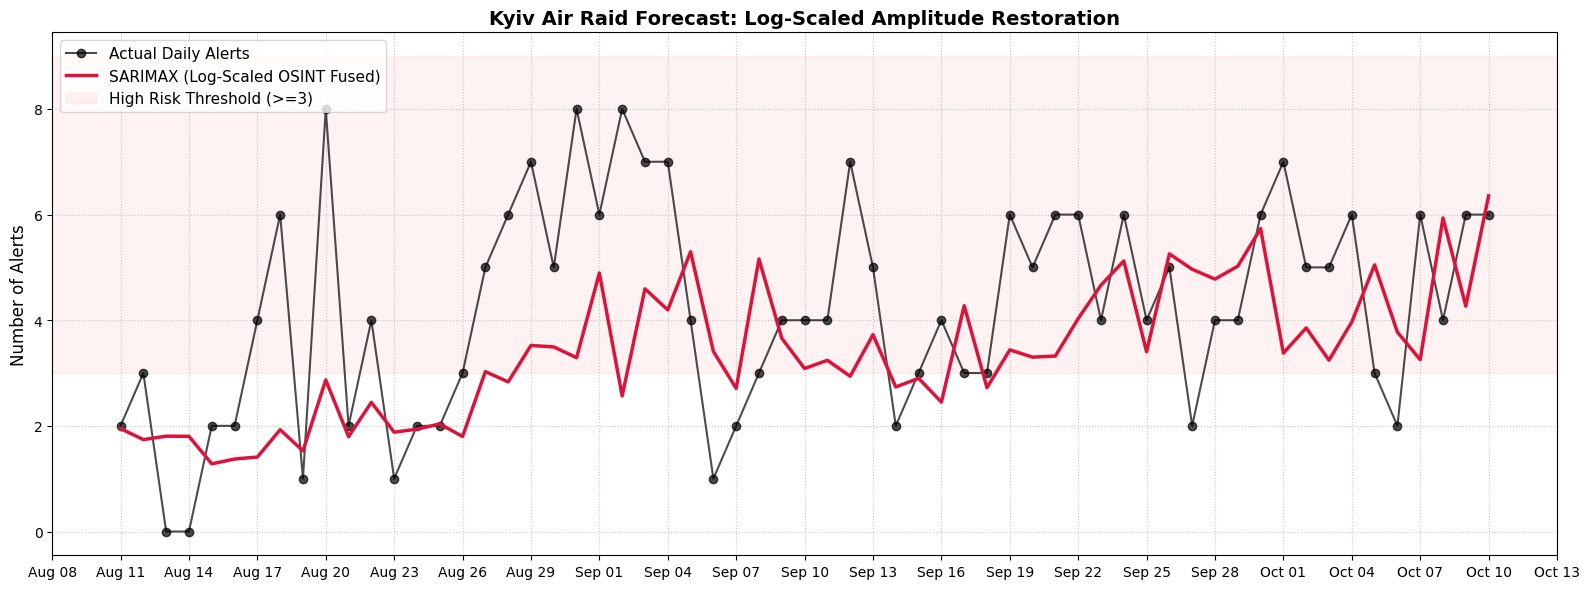

In [18]:
log_trainer = LogScaledRiskTrainer(fused_dataset, test_days=60)
y_test_actual, preds_restored = log_trainer.execute_log_forecast()

plot_unsqueezed_forecast(y_test_actual, preds_restored)